## IMPORTING LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import os
from keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf
from keras.models import Model, Sequential, load_model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D, BatchNormalization, GlobalAveragePooling2D,Activation,Input
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
! pip install seaborn
import seaborn as sns
import cv2


[notice] A new release of pip is available: 23.1.2 -> 23.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## DATA LOADING

In [2]:
data_dir=r"DATA"
cancer=[]
for file in os.listdir(data_dir):
    cancer+=[file]
print(cancer)
print(len(cancer))

['Colon_Adenocarcinoma', 'Colon_Benign_Tissue']
2


## PRPROCESSING

In [6]:
# Define your image dimensions and batch size
img_height = 224  
img_width = 224   
batch_size = 32  

# Create separate data generators for training and testing
train_datagen = ImageDataGenerator(
    rescale=1./224,
    validation_split=0.2
)

# Training data generator
train_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

# Testing data generator
test_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

Found 5408 images belonging to 2 classes.
Found 1352 images belonging to 2 classes.


## APPLYING CNN ALGORITHM

In [8]:
# Create a Sequential model, which is a linear stack of layers
model = Sequential()

# Add a 2D convolutional layer with 32 filters, a 3x3 kernel, 'Same' padding, ReLU activation,
# and input shape (img_height, img_width, 3) for RGB images
model.add(Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu', input_shape=(img_height,img_width, 3)))

# Add a MaxPooling layer with a 2x2 pool size
model.add(MaxPool2D(pool_size=(2,2)))

# Add another 2D convolutional layer with 64 filters and similar settings
model.add(Conv2D(filters=64, kernel_size=(3,3), padding='same', activation='relu'))
model.add(MaxPool2D(pool_size=(2,2), strides=(2,2)))
model.add(Conv2D(filters=96, kernel_size=(3,3), padding='same', activation='relu'))
model.add(MaxPool2D(pool_size=(2,2), strides=(2,2)))
model.add(Conv2D(filters=96, kernel_size=(3,3), padding='same', activation='relu'))
model.add(MaxPool2D(pool_size=(2,2), strides=(2,2)))
model.add(Flatten())

# Add a fully connected (dense) layer with 512 units and ReLU activation
model.add(Dense(512))
model.add(Activation('relu'))

# Add the final output layer with 5 units (assuming you have 5 classes) and softmax activation
model.add(Dense(2, activation="softmax"))

# Print a summary of the model architecture
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 224, 224, 32)      896       
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 112, 112, 32)     0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 112, 112, 64)      18496     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 56, 56, 64)       0         
 2D)                                                             
                                                                 
 conv2d_6 (Conv2D)           (None, 56, 56, 96)        55392     
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 28, 28, 96)      

In [10]:
model.compile(optimizer='Adam',loss="categorical_crossentropy",metrics=["accuracy"])
hist=model.fit(train_generator,epochs=10,validation_data=test_generator,verbose=1)

Epoch 1/10
169/169 [==============================] - 252s 1s/step - loss: 0.2812 - accuracy: 0.8879 - val_loss: 0.4865 - val_accuracy: 0.7899
Epoch 2/10
169/169 [==============================] - 251s 1s/step - loss: 0.1713 - accuracy: 0.9375 - val_loss: 0.1007 - val_accuracy: 0.9682
Epoch 3/10
169/169 [==============================] - 325s 2s/step - loss: 0.1502 - accuracy: 0.9456 - val_loss: 0.1491 - val_accuracy: 0.9379
Epoch 4/10
169/169 [==============================] - 421s 2s/step - loss: 0.0932 - accuracy: 0.9649 - val_loss: 0.0827 - val_accuracy: 0.9756
Epoch 5/10
169/169 [==============================] - 411s 2s/step - loss: 0.0577 - accuracy: 0.9793 - val_loss: 0.0687 - val_accuracy: 0.9734
Epoch 6/10
169/169 [==============================] - 405s 2s/step - loss: 0.0517 - accuracy: 0.9811 - val_loss: 0.0669 - val_accuracy: 0.9756
Epoch 7/10
169/169 [==============================] - 406s 2s/step - loss: 0.0066 - accuracy: 0.9982 - val_loss: 0.0495 - val_accuracy: 0.9852

## GRAPH:

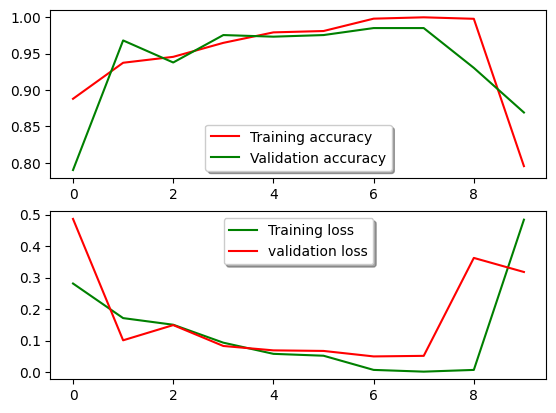

In [11]:
fig, ax = plt.subplots(2,1)
ax[0].plot(hist.history['accuracy'], color='r', label="Training accuracy")
ax[0].plot(hist.history['val_accuracy'], color='g',label="Validation accuracy")
legend = ax[0].legend(loc='best', shadow=True)

ax[1].plot(hist.history['loss'], color='g', label="Training loss")
ax[1].plot(hist.history['val_loss'], color='r', label="validation loss",axes =ax[1])
legend = ax[1].legend(loc='best', shadow=True)

In [12]:
model.evaluate(test_generator)
model.save("CNN.h5")

43/43 [==============================] - 23s 537ms/step - loss: 0.3178 - accuracy: 0.8691
